# A09 怎样自动决定拿钥匙、开门与送货的顺序？

初始在走廊，钥匙和包裹都在走廊，房门关闭。你要让程序从目标反推出可执行动作序列，并识别一份漏写“开门需要钥匙”的离线模型草稿。

先修：已完成 AI 基础课；会使用列表、字典、函数和 NumPy。涉及的新结构在本例分步解释。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 事实集合与动作三元组
状态是当前为真的事实集合。动作包含pre前提、add新增事实、delete删除事实。集合差与并集表达状态更新。未出现的事实按本模型视为假。

In [2]:
import json
import itertools
import math
import numpy as np
import pandas as pd

def save_results(metrics, recommendation):
    """只负责保存实际计算结果；决策逻辑在下文。"""
    def convert(value):
        return value.item() if hasattr(value, "item") else str(value)
    (OUT_DIR / "metrics.json").write_text(
        json.dumps(metrics, ensure_ascii=False, indent=2, default=convert), encoding="utf-8")
    (OUT_DIR / "决策建议.md").write_text(
        "# 本次运行的决策建议\n\n" + recommendation +
        "\n\n数据为本例明确给定的教学场景；结论仅对模型、目标与已检查条件成立。\n",
        encoding="utf-8")
    print(json.dumps(metrics, ensure_ascii=False, indent=2, default=convert))
    print(recommendation)

from collections import deque
def action(name,pre,add,delete):
    return dict(name=name,pre=set(pre),add=set(add),delete=set(delete))
actions=[action("take-key",["at-hall","key-hall"],["has-key"],["key-hall"]),
         action("open-door",["at-hall","has-key"],["door-open"],[]),
         action("take-package",["at-hall","package-hall"],["carrying"],["package-hall"]),
         action("enter-room",["at-hall","door-open"],["at-room"],["at-hall"]),
         action("leave-room",["at-room","door-open"],["at-hall"],["at-room"]),
         action("deliver",["at-room","carrying"],["delivered"],["carrying"])]
initial_state=frozenset(["at-hall","key-hall","package-hall"]); target={"delivered"}
def apply_action(state,rule):
    if not rule["pre"]<=set(state): raise ValueError("前提未满足："+rule["name"])
    return frozenset((set(state)-rule["delete"])|rule["add"])
print("初始事实",sorted(initial_state))


初始事实 ['at-hall', 'key-hall', 'package-hall']


## 2. 前向广度优先搜索
队列保存状态与已走动作。每个动作单位代价时BFS找到最少动作数；如果不同动作成本不同，需要换成带代价搜索。frozenset可以放入visited避免循环。

In [3]:
def plan_actions(start,goal,rules):
    queue=deque([(frozenset(start),[])]);visited={frozenset(start)}
    while queue:
        state,plan=queue.popleft()
        if set(goal)<=set(state): return plan,len(visited)
        for rule in rules:
            if rule["pre"]<=set(state):
                nxt=apply_action(state,rule)
                if nxt not in visited:
                    visited.add(nxt);queue.append((nxt,plan+[rule["name"]]))
    return None,len(visited)
plan,visited_count=plan_actions(initial_state,target,actions)
assert plan is not None and len(plan)==5
impossible,_=plan_actions(initial_state,{"teleported"},actions)
assert impossible is None
print("动作计划",plan)


动作计划 ['take-key', 'open-door', 'take-package', 'enter-room', 'deliver']


## 3. 按原任务写独立执行器
验证器不读取动作表中的pre/add/delete，而按房间、钥匙、门和包裹的业务规则执行。这能抓住动作模型遗漏前提的错误。验证器本身也用正例和反例检查。

In [4]:
def validate_business_plan(sequence):
    location="hall";key=False;door=False;carrying=False;delivered=False;key_on_floor=True;package_on_floor=True
    trace=[]
    for step,name in enumerate(sequence):
        ok=True
        if name=="take-key":
            ok=location=="hall" and key_on_floor
            if ok:key=True;key_on_floor=False
        elif name=="open-door":
            ok=location=="hall" and key
            if ok:door=True
        elif name=="take-package":
            ok=location=="hall" and package_on_floor
            if ok:carrying=True;package_on_floor=False
        elif name=="enter-room":
            ok=location=="hall" and door
            if ok:location="room"
        elif name=="leave-room":
            ok=location=="room" and door
            if ok:location="hall"
        elif name=="deliver":
            ok=location=="room" and carrying
            if ok:delivered=True;carrying=False
        else:ok=False
        trace.append(dict(step=step,action=name,valid=ok,location=location,key=key,door=door,carrying=carrying,delivered=delivered))
        if not ok:return False,trace
    return delivered,trace
valid,trace=validate_business_plan(plan)
assert valid
assert not validate_business_plan(["open-door","enter-room","deliver"])[0]
assert not validate_business_plan(["invent-action"])[0]


## 4. 对照PDDL，检查离线错误草稿
同目录domain.pddl与problem.pddl表达相同有限动作问题。本例没有安装外部PDDL求解器，不能声称已通过它；实际执行的是上面的STRIPS搜索。拓展草稿是人为构造的错误样例，不冒充模型实时输出。

In [5]:
import copy
draft=copy.deepcopy(actions)
draft[1]["pre"].remove("has-key")
draft_plan,_=plan_actions(initial_state,target,draft)
draft_ok,draft_trace=validate_business_plan(draft_plan)
assert not draft_ok and len(draft_plan)==4
(OUT_DIR/"离线错误草稿.json").write_text(json.dumps(draft,ensure_ascii=False,default=sorted,indent=2),encoding="utf-8")
(OUT_DIR/"计划.txt").write_text("\n".join(plan),encoding="utf-8")
pd.DataFrame(trace).to_csv(OUT_DIR/"状态追踪.csv",index=False,encoding="utf-8-sig")
pd.DataFrame(draft_trace).to_csv(OUT_DIR/"错误草稿检查.csv",index=False,encoding="utf-8-sig")
plt.barh(range(len(plan)),[1]*len(plan),left=range(len(plan)),color="#498a9c")
plt.yticks(range(len(plan)),plan);plt.xlabel("动作步")
plt.tight_layout();plt.savefig(OUT_DIR/"动作序列.png");plt.close()
save_results({"plan":plan,"action_count":len(plan),"visited_states":visited_count,
              "business_validator_pass":valid,"draft_plan":draft_plan,"draft_validator_pass":draft_ok,
              "external_pddl_solver_run":False},
             f"采用{len(plan)}步计划：{' → '.join(plan)}。独立业务执行检查通过。"
             f"漏写钥匙前提的草稿产生{len(draft_plan)}步计划，但独立检查拒绝；求解器只能解已写出的模型，不能自动补齐现实需求。")


{
  "plan": [
    "take-key",
    "open-door",
    "take-package",
    "enter-room",
    "deliver"
  ],
  "action_count": 5,
  "visited_states": 9,
  "business_validator_pass": true,
  "draft_plan": [
    "open-door",
    "take-package",
    "enter-room",
    "deliver"
  ],
  "draft_validator_pass": false,
  "external_pddl_solver_run": false
}
采用5步计划：take-key → open-door → take-package → enter-room → deliver。独立业务执行检查通过。漏写钥匙前提的草稿产生4步计划，但独立检查拒绝；求解器只能解已写出的模型，不能自动补齐现实需求。


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

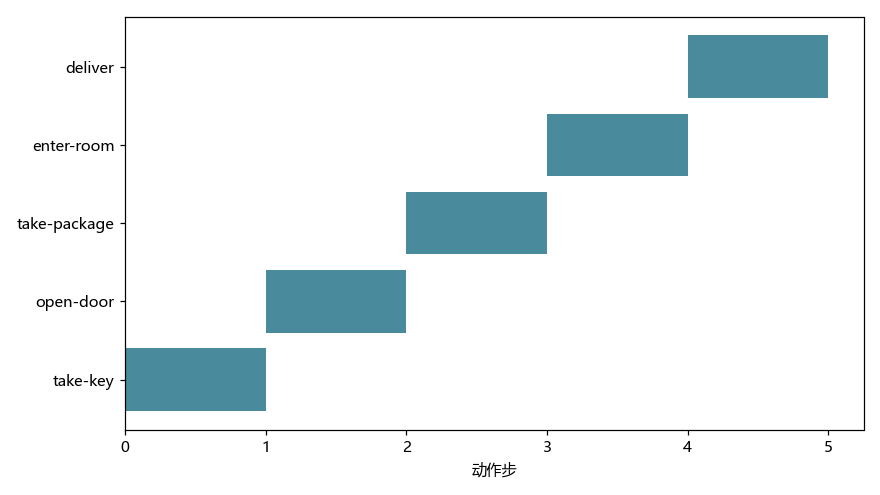

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
世界完全可观测、动作确定、单位代价且没有并行动作。PDDL文本提供阅读对照，未运行外部PDDL工具；离线错误草稿不是实时语言模型实验。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。